## Fase 1

In [3]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv('e-commerce-dataset.csv')
display(df.head())

df = df.dropna(subset=['Producto'])
df['Producto'] = df['Producto'].str.upper()
df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT']
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto'])


,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [4]:
df_merged = pd.merge(df, df, on='ID_Transaccion')

df_filtered = df_merged[df_merged['Producto_x'] < df_merged['Producto_y']]

interacciones = df_filtered.groupby(['Producto_x', 'Producto_y']).size().reset_index(name='Peso')

print("Top 5 combinaciones de productos:")
display(interacciones.sort_values(by='Peso', ascending=False).head())

Top 5 combinaciones de productos:


,Producto_x,Producto_y,Peso
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
38,MOUSE INALÁMBRICO,WEBCAM 1080P,361
40,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
31,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
42,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351


Producto Ancla: AUDÍFONOS BLUETOOTH con una centralidad de 1.0
Si el cliente añade 'TECLADO MECÁNICO RGB', debes recomendarle: 'MOUSEPAD XL' (Comprados juntos 359 veces)


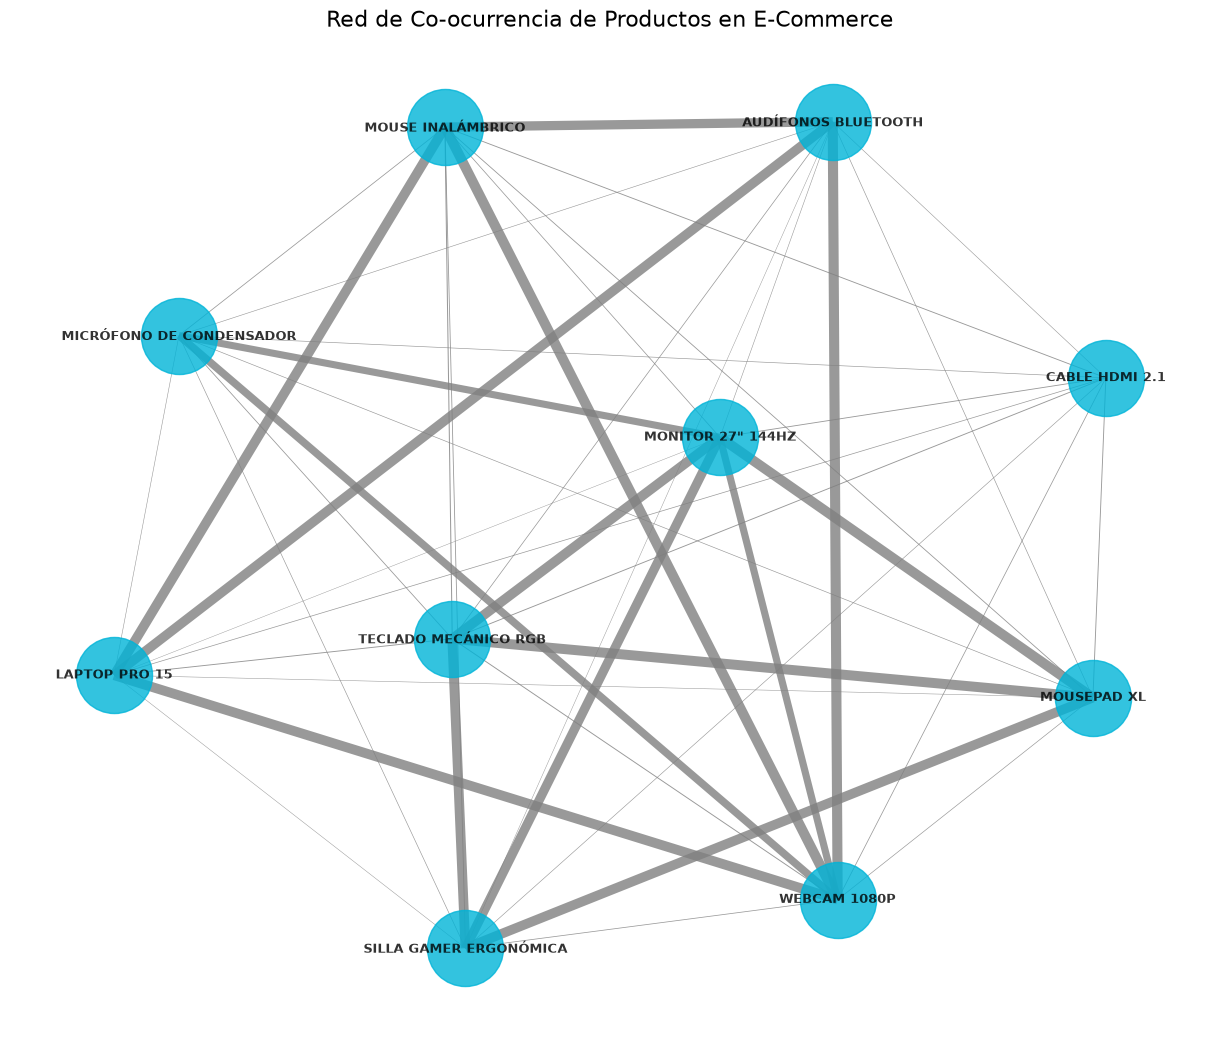

In [5]:
G_ecommerce = nx.from_pandas_edgelist(
    interacciones, 
    source='Producto_x', 
    target='Producto_y', 
    edge_attr='Peso', 
    create_using=nx.Graph()
)

centrality = nx.degree_centrality(G_ecommerce)
producto_ancla = max(centrality, key=centrality.get)
print(f"Producto Ancla: {producto_ancla} con una centralidad de {centrality[producto_ancla]}")


producto_objetivo = 'TECLADO MECÁNICO RGB'
vecinos = G_ecommerce[producto_objetivo]
recomendacion = max(vecinos, key=lambda x: vecinos[x]['Peso'])
peso_maximo = vecinos[recomendacion]['Peso']

print(f"Si el cliente añade '{producto_objetivo}', debes recomendarle: '{recomendacion}' (Comprados juntos {peso_maximo} veces)")

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_ecommerce, seed=42)

pesos = [d['Peso'] * 0.02 for (u, v, d) in G_ecommerce.edges(data=True)]

nx.draw(
    G_ecommerce, 
    pos, 
    with_labels=True, 
    node_color='#00b4d8', 
    node_size=3000, 
    font_size=9,
    font_color='black', 
    font_weight='bold', 
    width=pesos, 
    edge_color='gray',
    alpha=0.8
)

plt.title('Red de Co-ocurrencia de Productos en E-Commerce', fontsize=16)
plt.show()